In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import *

In [2]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/employee_attrition_20000_rows.csv")

In [3]:
df.head()

,employee_id,age,monthly_income,years_at_company,years_in_role,job_satisfaction,work_life_balance,overtime,business_travel,department,job_level,distance_from_home,training_times_last_year,promotion_last_5_years,attrition
0,EMP00001,53,76044.42,5.1,5.1,4.0,1,Yes,Non-Travel,Research & Development,Entry,4,0,Yes,0
1,EMP00002,54,64154.73,2.6,2.6,4.0,1,Yes,Travel_Frequently,Sales,Senior,39,3,No,0
2,EMP00003,32,69714.74,7.0,1.2,3.0,3,No,Travel_Rarely,Human Resources,Mid,1,1,No,0
3,EMP00004,48,74400.97,5.7,0.3,4.0,3,No,Travel_Rarely,Sales,Mid,25,4,No,0
4,EMP00005,50,91939.39,0.5,0.5,1.0,2,Yes,Travel_Frequently,Research & Development,Senior,30,3,No,0


In [4]:
df.shape

(20000, 15)

In [5]:
df.columns

Index(['employee_id', 'age', 'monthly_income', 'years_at_company',
       'years_in_role', 'job_satisfaction', 'work_life_balance', 'overtime',
       'business_travel', 'department', 'job_level', 'distance_from_home',
       'training_times_last_year', 'promotion_last_5_years', 'attrition'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   employee_id               20000 non-null  object 
 1   age                       20000 non-null  int64  
 2   monthly_income            19700 non-null  float64
 3   years_at_company          20000 non-null  float64
 4   years_in_role             20000 non-null  float64
 5   job_satisfaction          19800 non-null  float64
 6   work_life_balance         20000 non-null  int64  
 7   overtime                  19800 non-null  object 
 8   business_travel           20000 non-null  object 
 9   department                19800 non-null  object 
 10  job_level                 20000 non-null  object 
 11  distance_from_home        20000 non-null  int64  
 12  training_times_last_year  20000 non-null  int64  
 13  promotion_last_5_years    20000 non-null  object 
 14  attrit

In [8]:
df.describe()

,age,monthly_income,years_at_company,years_in_role,job_satisfaction,work_life_balance,distance_from_home,training_times_last_year,attrition
count,20000.000000,19700.000000,20000.000000,20000.000000,19800.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,39.953350,64924.937735,6.218175,2.908740,2.494949,2.496650,25.601300,2.999550,0.219550
std,11.815915,21787.962453,3.904905,1.876099,1.118593,1.115639,14.282333,2.000062,0.413952
min,20.000000,15000.000000,0.100000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,30.000000,50032.550000,3.300000,1.500000,1.000000,1.000000,13.000000,1.000000,0.000000
50%,40.000000,64765.040000,5.400000,2.500000,2.000000,2.000000,26.000000,3.000000,0.000000
75%,50.000000,79864.187500,8.300000,3.900000,3.000000,3.000000,38.000000,5.000000,0.000000
max,60.000000,151436.500000,33.000000,15.300000,4.000000,4.000000,50.000000,6.000000,1.000000


In [9]:
df.size

300000

In [10]:
df.isnull().sum()

employee_id                   0
age                           0
monthly_income              300
years_at_company              0
years_in_role                 0
job_satisfaction            200
work_life_balance             0
overtime                    200
business_travel               0
department                  200
job_level                     0
distance_from_home            0
training_times_last_year      0
promotion_last_5_years        0
attrition                     0
dtype: int64

In [14]:
df["monthly_income"]=df["monthly_income"].fillna(df["monthly_income"].mean())
df["job_satisfaction"]=df["job_satisfaction"].fillna(df["job_satisfaction"].mean())
df["overtime"]=df["overtime"].fillna(df["overtime"].mode()[0])
df["department"]=df["department"].fillna(df["department"].mode()[0])

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   employee_id               20000 non-null  object 
 1   age                       20000 non-null  int64  
 2   monthly_income            20000 non-null  float64
 3   years_at_company          20000 non-null  float64
 4   years_in_role             20000 non-null  float64
 5   job_satisfaction          20000 non-null  float64
 6   work_life_balance         20000 non-null  int64  
 7   overtime                  20000 non-null  object 
 8   business_travel           20000 non-null  object 
 9   department                20000 non-null  object 
 10  job_level                 20000 non-null  object 
 11  distance_from_home        20000 non-null  int64  
 12  training_times_last_year  20000 non-null  int64  
 13  promotion_last_5_years    20000 non-null  object 
 14  attrit

In [16]:
df.isnull().sum()

employee_id                 0
age                         0
monthly_income              0
years_at_company            0
years_in_role               0
job_satisfaction            0
work_life_balance           0
overtime                    0
business_travel             0
department                  0
job_level                   0
distance_from_home          0
training_times_last_year    0
promotion_last_5_years      0
attrition                   0
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(0)

In [20]:
X = df.drop(columns=["employee_id", "attrition"])
y = df["attrition"]

numeric_features = [
    "age", "monthly_income", "years_at_company",
    "years_in_role", "job_satisfaction",
    "work_life_balance", "distance_from_home",
    "training_times_last_year"]

categorical_features = [
    "overtime", "business_travel", "department",
    "job_level", "promotion_last_5_years"]

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42, stratify=y)

# Encoding and preprocessing

In [23]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)])

# Train Decision Tree

In [25]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
))])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','monthly_income','years_at_company',...,'distance_from_home', 'training_times_last_year','promotion_last_5_years']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'`

In [26]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Model evaluation

In [28]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.697
Precision: 0.3016627078384798
Recall: 0.28929384965831434
F1 Score: 0.29534883720930233
ROC-AUC: 0.5504765212417132


In [29]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.81      0.81      3122
           1       0.30      0.29      0.30       878

    accuracy                           0.70      4000
   macro avg       0.55      0.55      0.55      4000
weighted avg       0.69      0.70      0.69      4000



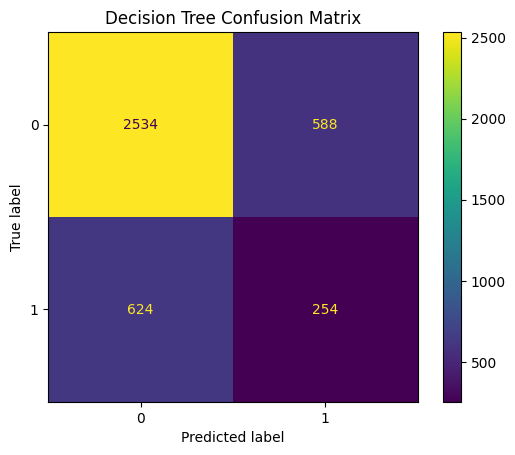

In [30]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Decision Tree Confusion Matrix")
plt.show()

# Hyperparameter tuning

In [32]:
param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 5, 8, 12, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5]}

grid = GridSearchCV(
    model,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

Fitting 5 folds for each of 90 candidates, totalling 450 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__criterion': ['gini', 'entropy'], 'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluatio

In [33]:
best_model = grid.best_estimator_
print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

Best Parameters: {'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Best CV Score: 0.4543386778451052


# Save model

In [34]:
joblib.dump( best_model,"employee_attrition_decision_tree.pkl")
print("Model saved successfully!")

Model saved successfully!
